# LastFM — eksperimen W&B, ablasi, dan checkpoint penulis

> Notebook tambahan dari konfigurasi 2 worker. Output W&B dan tabel tersimpan dipertahankan; ini bukan notebook audit utama. Ada output troubleshooting dari sesi Colab. Perbandingan dengan notebook ketat 4 worker bersifat deskriptif karena lingkungan dan patch tidak dikendalikan identik. Dataset mentah dan checkpoint tidak disertakan.

> Notebook memakai Google Colab Secret `WANDB_API_KEY`; jangan memasukkan key secara literal ke notebook. Jalankan training cell hanya jika memang ingin mengulang eksperimen.


# Reproduksi BSARec — dataset LastFM (Google Colab, T4)

Notebook ini mengikuti alur yang sama dengan Beauty: setup, konfigurasi, patch `main.py` (logging W&B), training BSARec dan SASRec (3 seed), backup ke Drive, parsing log, perbandingan dengan paper, ablasi alpha dan c, versi lingkungan, dan (opsional) evaluasi checkpoint penulis.

**Catatan penting**
- Notebook ini **hanya disusun**, belum dijalankan. Tidak ada hasil training yang diklaim di sini.
- Semua yang perlu diedit (nama data, hyperparameter, angka paper, seed) ada di **bagian B**, sel `B1`.
- Sel bertanda `!!! TODO !!!` berisi nilai yang belum bisa diverifikasi saat notebook disusun.

**Urutan pemakaian**
- Sesi pertama: A → B → C → D → E (backup) → F → G → H → I → J.
- **Kalau sesi baru (runtime putus):** jalankan **A, B, C, lalu E-restore, lewati D**, kemudian F dan seterusnya. Sel di D dan H aman diulang karena run yang log-nya sudah memuat hasil test akan dilewati.
- Jangan menjalankan "Run all" secara membabi buta: D dan H memakan waktu berjam-jam.

## A. Setup

Meng-clone repo, memasang paket, melihat isi folder `data/`, `output/`, `scripts/`, dan README, lalu mendeteksi file data LastFM.

*Kalau sesi baru, jalankan A, B, C lalu E-restore, lewati D.*

In [1]:
# ==============================================================================
# 1. TUJUAN: Masuk ke /content, clone repo BSARec bila belum ada, pindah ke /content/BSARec/src,
#    dan pasang paket pendukung (scipy, tqdm, wandb).
# 2. INPUT/PRASYARAT: Runtime Colab dengan GPU T4 dan internet aktif. Tidak ada sel lain yang
#    harus dijalankan lebih dulu.
# 3. OUTPUT: Folder /content/BSARec terisi. Pada run pertama tampil log git clone; pada run
#    berikutnya tidak ada clone ulang. pip -q hampir tidak mencetak apa pun (normal).
# 4. AMAN DIULANG?: AMAN DIULANG. Clone dilewati bila folder sudah ada, dan pip tidak memasang
#    ulang paket yang sudah ada.
# 5. ESTIMASI WAKTU: sekitar 1-2 menit.
# 6. KALAU ERROR: 'fatal: unable to access' berarti internet Colab bermasalah, jalankan ulang
#    sel. Bila pip memberi konflik versi, abaikan selama tidak berhenti dengan error merah. Bila
#    %cd gagal, folder repo belum ter-clone: hapus /content/BSARec lalu jalankan ulang.
# ==============================================================================

%cd /content
![ -d BSARec ] || git clone https://github.com/yehjin-shin/BSARec.git   # clone hanya jika folder BSARec belum ada
%cd /content/BSARec/src
!pip install -q scipy tqdm wandb   # -q = diam; paket yang sudah terpasang tidak diinstal ulang

/content
Cloning into 'BSARec'...
remote: Enumerating objects: 592, done.
remote: Counting objects: 100% (43/43), done.
remote: Compressing objects: 100% (23/23), done.
remote: Total 592 (delta 28), reused 20 (delta 20), pack-reused 549 (from 1)
Receiving objects: 100% (592/592), 859.10 MiB | 28.61 MiB/s, done.
Resolving deltas: 100% (136/136), done.
Updating files: 100% (384/384), done.
/content/BSARec/src


In [2]:
# ==============================================================================
# 1. TUJUAN: Melihat isi data/, output/, scripts/ dan README repo agar kita bisa memeriksa nama
#    file LastFM serta hyperparameter yang dianjurkan penulis.
# 2. INPUT/PRASYARAT: Sel A1 sudah dijalankan (posisi folder harus /content/BSARec/src).
# 3. OUTPUT: Daftar file. Yang normal: data/ berisi file seperti Beauty.txt,
#    Beauty_same_target.npy, dan semoga LastFM.txt; output/ kosong atau belum ada di sesi baru;
#    scripts/ mungkin tidak ada (README tidak menyebutnya). README dicetak penuh.
# 4. AMAN DIULANG?: AMAN DIULANG (hanya membaca).
# 5. ESTIMASI WAKTU: kurang dari 5 detik.
# 6. KALAU ERROR: 'No such file or directory' pada data/ berarti posisi folder salah: jalankan
#    ulang sel A1. Pesan fallback '(tidak ada ...)' pada output/ atau scripts/ itu normal, bukan
#    error.
# ==============================================================================

!ls data/
!ls output/ 2>/dev/null || echo "(output/ belum ada atau kosong - normal di sesi baru)"
!ls scripts/ 2>/dev/null || echo "(tidak ada folder scripts/ di repo ini)"
!cat ../README.md

Beauty_same_target.npy	Sports_and_Outdoors_same_target.npy
Beauty.txt		Sports_and_Outdoors.txt
LastFM_same_target.npy	Toys_and_Games_same_target.npy
LastFM.txt		Toys_and_Games.txt
ML-1M_same_target.npy	Yelp_same_target.npy
ML-1M.txt		Yelp.txt
process
BSARec_Beauty_best.log	BSARec_LastFM_best.log
BSARec_Beauty_best.pt	BSARec_LastFM_best.pt
(tidak ada folder scripts/ di repo ini)
<div align=center>
<h1>An Attentive Inductive Bias for Sequential Recommendation beyond the Self-Attention</h1>

![GitHub Repo stars](https://img.shields.io/github/stars/yehjin-shin/BSARec)
 [![arXiv](https://img.shields.io/badge/arXiv-2312.10325-b31b1b.svg)](https://arxiv.org/abs/2312.10325)

<div>
    <a href="https://yehjin-shin.github.io/" target="_blank">Yehjin Shin*</a>,
      <a href="https://www.jeongwhanchoi.com" target="_blank">Jeongwhan Choi*</a>,
      <a href="https://scholar.google.com/citations?user=foMLcAAAAAJ&hl=en" target="_blank">Hyowon Wi</a>,
      <a href="https://sites.google.com/view/nose

In [3]:
# ==============================================================================
# 1. TUJUAN: Mendeteksi file data LastFM di data/ TANPA memedulikan huruf besar/kecil, supaya
#    nama yang tepat (mis. LastFM.txt vs lastfm.txt) bisa disalin ke DATA_NAME di sel B1.
# 2. INPUT/PRASYARAT: Sel A1 sudah dijalankan. Belum membutuhkan konfigurasi dari bagian B.
# 3. OUTPUT: Daftar file di data/ yang namanya memuat 'lastfm'. Yang normal: minimal satu file
#    .txt (dan mungkin *_same_target.npy). Bila tidak ada, sel mencetak seluruh isi data/ lalu
#    berhenti dengan exception.
# 4. AMAN DIULANG?: AMAN DIULANG (hanya membaca).
# 5. ESTIMASI WAKTU: kurang dari 1 detik.
# 6. KALAU ERROR: FileNotFoundError berarti file data LastFM tidak ada di repo hasil clone.
#    Periksa cetakan isi data/ di bawah: bisa jadi namanya berbeda (mis. 'LastFM.txt' vs
#    'lastfm.txt'), atau data harus diproses/diunduh dulu sesuai bagian Dataset di README.
# ==============================================================================

import os

DATA_DIR = "/content/BSARec/src/data"   # folder data bawaan repo
semua_file = sorted(os.listdir(DATA_DIR))   # isi lengkap data/ (dipakai juga untuk pesan error)
kandidat = [f for f in semua_file if "lastfm" in f.lower()]   # cocokkan tanpa peduli huruf besar/kecil

if not kandidat:
    print("Isi folder data/ :")
    for f in semua_file:
        print("  -", f)
    raise FileNotFoundError("Tidak ada file LastFM di data/. Lihat daftar di atas, lalu perbaiki nama atau siapkan datanya.")

print("Kandidat file LastFM di data/ :")
for f in kandidat:
    print("  -", f)
print("\nSalin nama dasar yang tepat (tanpa .txt) ke DATA_NAME di sel B1, dengan huruf besar/kecil yang sama persis.")

Kandidat file LastFM di data/ :
  - LastFM.txt
  - LastFM_same_target.npy

Salin nama dasar yang tepat (tanpa .txt) ke DATA_NAME di sel B1, dengan huruf besar/kecil yang sama persis.


## B. Konfigurasi

Dua sel baca-saja pertama menampilkan hyperparameter dari repo. Setelah itu **satu sel konfigurasi (B1)** berisi semua variabel yang boleh diedit, diikuti sel verifikasi (B2).

**Soal hyperparameter LastFM:** README repo hanya memberi contoh Beauty (`--lr 0.0005 --alpha 0.7 --c 5 --num_attention_heads 1`). Nilai Beauty **tidak dipakai** untuk LastFM. Saat notebook disusun, isi `scripts/` tidak bisa diperiksa, jadi nilai awal di B1 diambil dari **Tabel 6 paper BSARec** (LastFM: alpha 0.9, c 3, heads 1, lr 0.001) dan ditandai `!!! TODO !!!` agar dicocokkan dengan keluaran sel B0.

*Kalau sesi baru, jalankan A, B, C lalu E-restore, lewati D.*

In [4]:
# ==============================================================================
# 1. TUJUAN: Menampilkan semua yang ada di scripts/, semua baris yang menyebut LastFM di
#    README/scripts, dan daftar argumen CLI beserta default di utils.py. Dipakai untuk
#    mencocokkan hyperparameter LastFM di sel B1 dan memastikan --num_workers memang ada.
# 2. INPUT/PRASYARAT: Sel A1 sudah dijalankan.
# 3. OUTPUT: Isi scripts/ (bila ada), baris-baris yang mengandung 'lastfm', dan baris
#    add_argument dari utils.py. Yang normal: daftar argumen mencakup lr, alpha, c,
#    num_attention_heads, max_seq_length, batch_size, epochs, patience, num_workers, dst. Bila
#    tidak ada baris LastFM, hyperparameter di B1 tetap berstatus TODO.
# 4. AMAN DIULANG?: AMAN DIULANG (hanya membaca).
# 5. ESTIMASI WAKTU: kurang dari 5 detik.
# 6. KALAU ERROR: Pesan '(tidak ada ...)' berarti scripts/ tidak ada atau tidak menyebut LastFM:
#    itu bukan error, hanya berarti nilai di B1 belum bisa diverifikasi dari repo. Bila
#    add_argument tidak memuat num_workers, set NUM_WORKERS = None di B1.
# ==============================================================================

!cat scripts/* 2>/dev/null || echo "(tidak ada isi scripts/)"
!grep -rn -i "lastfm" ../README.md scripts/ 2>/dev/null || echo "(tidak ada baris LastFM di README atau scripts/)"
!grep -n "add_argument" utils.py   # daftar semua argumen CLI dan nilai default-nya

(tidak ada isi scripts/)
../README.md:39:- For ML-1M and LastFM, we processed the data according to the procedure outlined in [this code](https://github.com/RUCAIBox/CIKM2020-S3Rec/blob/master/data/data_process.py).
(tidak ada baris LastFM di README atau scripts/)
56:    parser.add_argument("--data_dir", default="./data/", type=str)
57:    parser.add_argument("--output_dir", default="output/", type=str)
58:    parser.add_argument("--data_name", default="Beauty", type=str)
59:    parser.add_argument("--do_eval", action="store_true")
60:    parser.add_argument("--load_model", default=None, type=str)
61:    parser.add_argument("--train_name", default=get_local_time(), type=str)
62:    parser.add_argument("--num_items", default=10, type=int)
63:    parser.add_argument("--num_users", default=10, type=int)
66:    parser.add_argument("--lr", default=0.001, type=float, help="learning rate of adam")
67:    parser.add_argument("--batch_size", default=256, type=int, help="number of batch_size")
6

In [5]:
# ==============================================================================
# 1. TUJUAN: SATU-SATUNYA sel konfigurasi: nama data, hyperparameter LastFM, seed, jumlah
#    worker, angka paper, grid ablasi, dan lokasi backup. Sel lain hanya MEMBACA variabel dari
#    sini.
# 2. INPUT/PRASYARAT: Sel A1-A3 dan B0 sudah dijalankan; nilai DATA_NAME harus disesuaikan
#    dengan keluaran A3.
# 3. OUTPUT: Cetakan ringkasan konfigurasi dan pengingat TODO. Tidak ada file yang dibuat. Yang
#    normal: ringkasan menunjukkan lr=0.001, alpha=0.9, c=3, heads=1, SEEDS=[42, 43, 44].
# 4. AMAN DIULANG?: AMAN DIULANG (hanya mengisi variabel). Wajib dijalankan ulang setelah sesi
#    baru atau setelah mengedit nilai.
# 5. ESTIMASI WAKTU: kurang dari 1 detik.
# 6. KALAU ERROR: NameError di sel lain berarti sel ini belum dijalankan di sesi ini.
#    AssertionError berarti ABLASI_SEED tidak ada di SEEDS: samakan.
# ==============================================================================

import os

# ----- Lokasi -----
SRC_DIR = "/content/BSARec/src"                 # semua perintah dijalankan dari sini
BACKUP_DIR = "/content/drive/MyDrive/BSARec_backup"   # tujuan backup di Google Drive

# ----- Dataset -----
# !!! TODO !!! Harus SAMA PERSIS (huruf besar/kecil) dengan data/<DATA_NAME>.txt - cek keluaran sel A3.
DATA_NAME = "LastFM"

# ----- Hyperparameter BSARec untuk LastFM -----
# !!! TODO: cocokkan dengan scripts/README repo !!!
# Sumber nilai di bawah: Tabel 6 paper BSARec (arXiv 2312.10325), kolom LastFM:
#   alpha 0.9, c 3, heads 1, lr 1e-3. README repo tidak memuat perintah LastFM dan isi scripts/
#   tidak bisa diperiksa saat notebook disusun. Bandingkan dengan keluaran sel B0, lalu ubah di sini bila beda.
# JANGAN pakai nilai Beauty (lr 0.0005, alpha 0.7, c 5) untuk LastFM.
LR = 0.001
ALPHA = 0.9
C = 3
NUM_HEADS = 1

# ----- Hyperparameter SASRec untuk LastFM -----
# !!! TODO !!! Belum ada sumber resmi untuk SASRec-LastFM; sementara disamakan dengan BSARec agar adil. Verifikasi di repo/paper.
SASREC_LR = 0.001
SASREC_HEADS = 1

# Argumen tambahan untuk SEMUA run, mis. ["--max_seq_length", "50"]. Default repo (hidden_size 64, 2 layer, max_seq_length 50,
# batch_size 256, patience 10, epochs 200, dropout 0.5) sudah dipakai bila dikosongkan.
EXTRA_ARGS = []

# ----- Eksperimen -----
SEEDS = [42, 43, 44]
NUM_WORKERS = 2            # sistem hanya menyarankan 2 worker; set None bila utils.py tidak punya --num_workers
FORCE_RERUN = False        # False: lewati run yang log-nya sudah memuat hasil test. True: jalankan ulang semua (log lama diberi akhiran .lama)
EPOCH_PERKIRAAN = 50       # perkiraan epoch sampai early stopping (hanya untuk estimasi waktu)

# ----- Ablasi (bagian H) -----
ABLASI_SEED = 42
ALPHA_GRID = [0.1, 0.3, 0.5, 0.7, 0.9]
C_GRID = [1, 3, 5, 7, 9]

# ----- Angka paper: Table 2 (full ranking, tanpa negative sampling) untuk LastFM -----
# Urutan: HR@5, NDCG@5, HR@10, NDCG@10, HR@20, NDCG@20. Isi None bila tidak yakin (kode hilir tahan None -> gap = NaN).
# Sumber: Table 2 paper BSARec (arXiv 2312.10325), baris LastFM, disalin dari versi HTML (ar5iv).
# TODO: cocokkan sekali lagi dengan PDF paper sebelum masuk laporan. JANGAN tertukar dengan Table 9 (99 negative sampling).
PAPER = {
    "BSARec": [0.0523, 0.0344, 0.0807, 0.0435, 0.1174, 0.0526],
    "SASRec": [0.0413, 0.0284, 0.0633, 0.0355, 0.0927, 0.0429],
}
METRICS = ["HR@5", "NDCG@5", "HR@10", "NDCG@10", "HR@20", "NDCG@20"]

# ----- Pemeriksaan kecil + ringkasan -----
assert ABLASI_SEED in SEEDS, "ABLASI_SEED harus salah satu dari SEEDS"
assert all(len(v) == 6 for v in PAPER.values()), "Tiap entri PAPER harus 6 angka (atau None)"
print(f"DATA_NAME={DATA_NAME} | BSARec: lr={LR}, alpha={ALPHA}, c={C}, heads={NUM_HEADS} | SASRec: lr={SASREC_LR}, heads={SASREC_HEADS}")
print(f"SEEDS={SEEDS} | NUM_WORKERS={NUM_WORKERS} | FORCE_RERUN={FORCE_RERUN} | EXTRA_ARGS={EXTRA_ARGS}")
print("!!! TODO !!! Hyperparameter LastFM di atas dari Tabel 6 paper, BELUM dicocokkan dengan scripts/README repo. Bandingkan dengan sel B0.")

DATA_NAME=LastFM | BSARec: lr=0.001, alpha=0.9, c=3, heads=1 | SASRec: lr=0.001, heads=1
SEEDS=[42, 43, 44] | NUM_WORKERS=2 | FORCE_RERUN=False | EXTRA_ARGS=[]
!!! TODO !!! Hyperparameter LastFM di atas dari Tabel 6 paper, BELUM dicocokkan dengan scripts/README repo. Bandingkan dengan sel B0.


In [6]:
# ==============================================================================
# 1. TUJUAN: Verifikasi ketat bahwa data/<DATA_NAME>.txt ada (dan melaporkan *_same_target.npy).
#    Bila tidak ada, cetak isi data/ lalu hentikan notebook dengan exception agar tidak lanjut
#    diam-diam.
# 2. INPUT/PRASYARAT: Sel B1 sudah dijalankan.
# 3. OUTPUT: Cetakan 'OK' untuk file .txt. Untuk _same_target.npy: 'ada' atau 'tidak ada' (hanya
#    dipakai DuoRec/FEARec; tidak wajib untuk BSARec/SASRec).
# 4. AMAN DIULANG?: AMAN DIULANG (hanya membaca).
# 5. ESTIMASI WAKTU: kurang dari 1 detik.
# 6. KALAU ERROR: FileNotFoundError: DATA_NAME di B1 tidak cocok dengan nama file (perhatikan
#    huruf besar/kecil). Salin nama dari keluaran A3, jalankan ulang B1 lalu sel ini.
# ==============================================================================

import os

os.chdir(SRC_DIR)   # pastikan posisi kerja benar (penting di sesi baru)

data_txt = os.path.join(SRC_DIR, "data", f"{DATA_NAME}.txt")                  # file interaksi utama
data_npy = os.path.join(SRC_DIR, "data", f"{DATA_NAME}_same_target.npy")      # opsional (kontrastif)

if not os.path.exists(data_txt):
    print("Isi folder data/ :")
    for f in sorted(os.listdir(os.path.join(SRC_DIR, "data"))):
        print("  -", f)
    raise FileNotFoundError(f"{data_txt} tidak ditemukan. Perbaiki DATA_NAME di sel B1 (huruf besar/kecil harus sama persis).")

print("OK  :", data_txt)
print("same_target.npy:", "ada" if os.path.exists(data_npy) else "tidak ada (tidak masalah untuk BSARec/SASRec)")

OK  : /content/BSARec/src/data/LastFM.txt
same_target.npy: ada


## C. Login W&B dan patch `main.py`

Empat sel: (C1) login W&B tanpa menuliskan API key di notebook, (C2) backup `main.py` asli, (C3) menimpa `main.py` dengan versi yang menambah logging W&B, (C4) fungsi bantu (pembaca log dan pemanggil training) yang dipakai bagian D, F, dan H.

Hanya `main.py` yang diubah; model, dataset, dan trainer tidak disentuh.

*Kalau sesi baru, jalankan A, B, C lalu E-restore, lewati D.*

In [7]:
# ==============================================================================
# 1. TUJUAN: Login ke Weights & Biases lewat getpass. API key tidak ditulis di notebook dan
#    tidak dicetak; hanya panjangnya yang ditampilkan.
# 2. INPUT/PRASYARAT: Sel A1 dan B1 sudah dijalankan. Siapkan API key dari
#    https://wandb.ai/authorize.
# 3. OUTPUT: Kotak input tersembunyi muncul. Setelah diisi tercetak 'panjang key: ...' (sekitar
#    86 untuk key format baru, bisa lebih pendek untuk format lama) dan pesan login berhasil.
# 4. AMAN DIULANG?: AMAN DIULANG (login ulang tidak merusak apa pun; key harus dimasukkan lagi
#    tiap sesi baru).
# 5. ESTIMASI WAKTU: sekitar 10 detik.
# 6. KALAU ERROR: 'API key must have 40+ characters' atau login gagal: key salah atau terpotong
#    saat disalin, ambil ulang dan tempel utuh. Jangan menempel key ke sel kode, selalu lewat
#    kotak input.
# ==============================================================================

import os, getpass, wandb

os.environ.pop("WANDB_API_KEY", None)      # buang key lama dari environment agar tidak bentrok
key = getpass.getpass("W&B API key: ").strip()   # input tersembunyi; .strip() membuang spasi/enter ikut tertempel
print("panjang key:", len(key))             # hanya panjangnya, BUKAN isinya
if len(key) < 40:
    print("PERINGATAN: key terlalu pendek, kemungkinan salah salin.")
wandb.login(key=key, relogin=True)          # relogin=True memaksa login ulang dengan key ini
del key                                     # hapus dari memori kernel

W&B API key: ··········
panjang key: 86


/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: rusdiasputre (rusdiasputre-brawijaya-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


In [8]:
# ==============================================================================
# 1. TUJUAN: Membuat cadangan main.py asli sebagai main_backup.py (hanya sekali) sebelum
#    ditimpa.
# 2. INPUT/PRASYARAT: Posisi folder /content/BSARec/src (sel A1).
# 3. OUTPUT: File main_backup.py muncul di src/. Tidak ada cetakan (normal).
# 4. AMAN DIULANG?: AMAN DIULANG. Backup dibuat hanya jika main_backup.py belum ada, jadi versi
#    asli tidak pernah tertimpa oleh versi yang sudah dipatch.
# 5. ESTIMASI WAKTU: kurang dari 1 detik.
# 6. KALAU ERROR: 'No such file' berarti posisi folder salah: jalankan ulang sel A1. Bila
#    main_backup.py sudah berisi versi yang SUDAH dipatch (mis. salah jalankan urutan), hapus
#    main_backup.py lalu `git checkout main.py` dan ulangi dari sini.
# ==============================================================================

%cd /content/BSARec/src
![ -f main_backup.py ] || cp main.py main_backup.py   # salin hanya bila backup belum ada

/content/BSARec/src


**Sel C3 — patch `main.py` (`%%writefile`)**. Karena `%%writefile` harus menjadi baris pertama sel, blok komentar standar ditaruh di sini, bukan di dalam sel:

1. **TUJUAN:** menimpa `main.py` dengan versi asli repo yang ditambah `wandb.init`, `wandb.log` per epoch validasi, `wandb.log` hasil test, dan `wandb.finish`. Kurva `valid/*` dan `test/*` akan muncul di project `bsarec-repro`.
2. **INPUT/PRASYARAT:** sel C2 sudah dijalankan (backup ada), posisi folder `/content/BSARec/src`.
3. **OUTPUT:** pesan `Writing main.py`. Tidak ada output lain.
4. **AMAN DIULANG?** Aman: isinya selalu sama persis, dan versi asli tetap tersimpan di `main_backup.py`. **Jangan jalankan saat ada training yang sedang berjalan.**
5. **ESTIMASI WAKTU:** kurang dari 1 detik.
6. **KALAU ERROR:** `Permission denied` / folder tidak ditemukan berarti posisi folder salah, jalankan ulang A1. Bila training kemudian gagal dengan `ImportError`, repo-mu berbeda versi dari yang dipakai untuk patch ini: pulihkan dengan `!cp main_backup.py main.py` dan periksa nama fungsi di `dataset.py`/`utils.py`.

Isinya **tidak boleh diubah** (sudah sesuai versi yang dipakai di Beauty).

In [9]:
%%writefile main.py
import os
import torch
import numpy as np
import wandb

from model import MODEL_DICT
from trainers import Trainer
from utils import EarlyStopping, check_path, set_seed, parse_args, set_logger
from dataset import get_seq_dic, get_dataloder, get_rating_matrix

def main():

    args = parse_args()
    log_path = os.path.join(args.output_dir, args.train_name + '.log')
    logger = set_logger(log_path)

    set_seed(args.seed)
    check_path(args.output_dir)

    os.environ["CUDA_VISIBLE_DEVICES"] = args.gpu_id
    args.cuda_condition = torch.cuda.is_available() and not args.no_cuda

    seq_dic, max_item, num_users = get_seq_dic(args)
    args.item_size = max_item + 1
    args.num_users = num_users + 1

    args.checkpoint_path = os.path.join(args.output_dir, args.train_name + '.pt')
    args.same_target_path = os.path.join(args.data_dir, args.data_name+'_same_target.npy')
    train_dataloader, eval_dataloader, test_dataloader = get_dataloder(args,seq_dic)

    logger.info(str(args))
    model = MODEL_DICT[args.model_type.lower()](args=args)
    logger.info(model)
    trainer = Trainer(model, train_dataloader, eval_dataloader, test_dataloader, args, logger)

    args.valid_rating_matrix, args.test_rating_matrix = get_rating_matrix(args.data_name, seq_dic, max_item)

    if args.do_eval:
        if args.load_model is None:
            logger.info(f"No model input!")
            exit(0)
        else:
            args.checkpoint_path = os.path.join(args.output_dir, args.load_model + '.pt')
            trainer.load(args.checkpoint_path)

            logger.info(f"Load model from {args.checkpoint_path} for test!")
            scores, result_info = trainer.test(0)
            args.checkpoint_path = os.path.join(args.output_dir, args.train_name + '.pt')

    else:
        cfg = {k: v for k, v in vars(args).items() if isinstance(v, (int, float, str, bool))}
        wandb.init(project="bsarec-repro", name=args.train_name, config=cfg)

        early_stopping = EarlyStopping(args.checkpoint_path, logger=logger, patience=args.patience, verbose=True)
        for epoch in range(args.epochs):

            trainer.train(epoch)
            scores, _ = trainer.valid(epoch)

            wandb.log({
                "epoch": epoch,
                "valid/HR@5": scores[0], "valid/NDCG@5": scores[1],
                "valid/HR@10": scores[2], "valid/NDCG@10": scores[3],
                "valid/HR@20": scores[4], "valid/NDCG@20": scores[5]
            })

            early_stopping(np.array(scores[-1:]), trainer.model)
            if early_stopping.early_stop:
                logger.info("Early stopping")
                break

        logger.info("---------------Test Score---------------")
        trainer.model.load_state_dict(torch.load(args.checkpoint_path))
        scores, result_info = trainer.test(0)

        wandb.log({
            "test/HR@5": scores[0], "test/NDCG@5": scores[1],
            "test/HR@10": scores[2], "test/NDCG@10": scores[3],
            "test/HR@20": scores[4], "test/NDCG@20": scores[5]
        })
        wandb.finish()

    logger.info(args.train_name)
    logger.info(result_info)

if __name__ == '__main__':
    main()

Overwriting main.py


In [10]:
# ==============================================================================
# 1. TUJUAN: Mendefinisikan fungsi bantu yang dipakai bagian D, F, dan H: pembaca hasil dari log
#    (ambil_hasil_test), pengukur durasi per epoch, penyusun argumen CLI, dan pemanggil training
#    (jalankan_run) yang tidak berhenti walau satu run gagal dan melewati run yang sudah
#    selesai.
# 2. INPUT/PRASYARAT: Sel B1 dan C3 sudah dijalankan (butuh DATA_NAME, SEEDS, LR, dst. dan
#    main.py yang sudah dipatch).
# 3. OUTPUT: Tidak ada cetakan; hanya mendefinisikan fungsi. Yang normal: sel selesai tanpa
#    output.
# 4. AMAN DIULANG?: AMAN DIULANG (hanya definisi fungsi). Wajib dijalankan ulang di sesi baru
#    (bagian dari urutan A, B, C).
# 5. ESTIMASI WAKTU: kurang dari 1 detik.
# 6. KALAU ERROR: NameError pada sel lain: sel ini belum dijalankan di sesi ini. Bila format log
#    berubah sehingga hasil tidak terbaca, cek manual baris sesudah 'Test Score' di
#    output/<train_name>.log.
# ==============================================================================

import os, re, ast, sys, time, subprocess
from datetime import datetime

MARKER_TEST = "Test Score"   # penanda awal blok hasil test di log (dari main.py: '---------------Test Score---------------')


def path_log(train_name):
    # lokasi file log sebuah run
    return os.path.join(SRC_DIR, "output", train_name + ".log")


def ambil_hasil_test(train_name):
    # Mengembalikan [HR@5, NDCG@5, HR@10, NDCG@10, HR@20, NDCG@20] hasil TEST akhir, atau None bila log belum selesai/tidak ada.
    # JEBAKAN: baris dict ber-'HR@5' juga muncul di tiap epoch validasi dan diulang di akhir log,
    # jadi kita ambil dict pertama SESUDAH penanda 'Test Score', bukan baris pertama/terakhir yang memuat HR@5.
    p = path_log(train_name)
    if not os.path.exists(p):
        return None
    with open(p, encoding="utf-8", errors="ignore") as f:
        baris = f.read().splitlines()
    idx = [i for i, b in enumerate(baris) if MARKER_TEST in b]   # semua posisi penanda
    if not idx:
        return None                                               # belum sampai tahap test
    for b in baris[idx[-1] + 1:]:                                 # pakai penanda TERAKHIR (bila log pernah ditambah)
        if "'HR@5'" in b and "{" in b:
            try:
                d = ast.literal_eval(b[b.index("{"):])            # potong mulai karakter '{' lalu parse sebagai dict Python
                # 'Epoch': 0 di baris ini hanya placeholder dari trainer.test(0), BUKAN epoch ke-0
                return [float(d[m]) for m in METRICS]             # nilai di log berupa string -> float
            except (ValueError, SyntaxError, KeyError):
                continue
    return None


def sudah_selesai(train_name):
    # True bila log sudah memuat hasil test (dipakai untuk melewati run yang sudah beres)
    return ambil_hasil_test(train_name) is not None


def durasi_per_epoch(train_name):
    # Rata-rata selisih waktu antar baris validasi berurutan (= waktu 1 epoch: training + evaluasi). None bila tak bisa dihitung.
    p = path_log(train_name)
    if not os.path.exists(p):
        return None
    with open(p, encoding="utf-8", errors="ignore") as f:
        baris = f.read().splitlines()
    idx = [i for i, b in enumerate(baris) if MARKER_TEST in b]
    batas = idx[-1] if idx else len(baris)                        # hanya baris SEBELUM blok test
    waktu = []
    for b in baris[:batas]:
        if "'HR@5'" in b and "{" in b:
            m = re.match(r"^(\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}),(\d{3})", b)   # format 'YYYY-MM-DD HH:MM:SS,mmm - ...'
            if m:
                waktu.append(datetime.strptime(m.group(1), "%Y-%m-%d %H:%M:%S").timestamp() + int(m.group(2)) / 1000)
    if len(waktu) < 2:
        return None
    selisih = [b - a for a, b in zip(waktu[:-1], waktu[1:])]
    return sum(selisih) / len(selisih)


def argumen_umum(seed, train_name, epochs=None):
    # argumen yang sama untuk semua run
    a = ["--seed", str(seed), "--train_name", train_name]
    if NUM_WORKERS is not None:
        a += ["--num_workers", str(NUM_WORKERS)]
    if epochs is not None:
        a += ["--epochs", str(epochs)]
    return a + [str(x) for x in EXTRA_ARGS]


def args_bsarec(seed, train_name, alpha=None, c=None, epochs=None):
    # None -> pakai ALPHA/C dari B1; nilai lain dipakai untuk ablasi
    alpha = ALPHA if alpha is None else alpha
    c = C if c is None else c
    return ["--lr", str(LR), "--alpha", str(alpha), "--c", str(c),
            "--num_attention_heads", str(NUM_HEADS)] + argumen_umum(seed, train_name, epochs)


def args_sasrec(seed, train_name, epochs=None):
    return ["--model_type", "SASRec", "--lr", str(SASREC_LR),
            "--num_attention_heads", str(SASREC_HEADS)] + argumen_umum(seed, train_name, epochs)


def jalankan_run(train_name, args_list, paksa=False):
    # Menjalankan 'python main.py ...' sebagai subprocess dan menampilkan outputnya langsung.
    # Tidak melempar error bila run gagal (kecuali dihentikan manual), supaya loop tetap lanjut.
    if not (FORCE_RERUN or paksa) and sudah_selesai(train_name):
        print(f"[LEWATI] {train_name}: log sudah memuat hasil test.")
        return {"nama": train_name, "status": "dilewati", "detik": 0.0}
    lp = path_log(train_name)
    if os.path.exists(lp):
        os.replace(lp, lp + ".lama")   # log lama (selesai/terputus) disingkirkan agar log baru bersih; .lama tidak ikut backup *.log
    cmd = [sys.executable, "-u", "main.py", "--data_name", DATA_NAME] + args_list   # -u = output tidak ditahan buffer
    print("[JALAN ]", " ".join(cmd))
    t0 = time.time()
    proc = None
    try:
        proc = subprocess.Popen(cmd, cwd=SRC_DIR, stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
        while True:
            potongan = proc.stdout.read1(4096)                    # baca mentah agar progress bar tqdm (\r) tampil wajar
            if not potongan:
                break
            sys.stdout.write(potongan.decode("utf-8", errors="replace"))
            sys.stdout.flush()
        kode = proc.wait()
        if kode == 0 and sudah_selesai(train_name):
            status = "selesai"
        else:
            status = f"GAGAL (kode keluar {kode}; log belum memuat hasil test)"
    except KeyboardInterrupt:
        if proc is not None:
            proc.kill()
        print(f"[DIHENTIKAN MANUAL] {train_name}")
        raise                                                     # hentikan seluruh loop bila kamu menekan Stop
    except Exception as e:                                        # error lain: catat, jangan hentikan loop
        status = f"GAGAL ({type(e).__name__}: {e})"
    detik = time.time() - t0
    print(f"[{status.upper()}] {train_name} - {detik / 60:.1f} menit\n")
    return {"nama": train_name, "status": status, "detik": detik}


def cetak_ringkasan(daftar):
    # tampilkan status semua run dalam satu loop
    print("\n===== RINGKASAN =====")
    for r in daftar:
        print(f"{r['nama']:<40} {r['status']:<45} {r['detik'] / 60:6.1f} menit")

## D. Training dengan W&B

Urutan: (D1) tes pendek 2 epoch untuk mengukur durasi per epoch dan memastikan kurva muncul di dashboard W&B, (D2) BSARec untuk semua seed, (D3) SASRec untuk semua seed.

- Nama run **unik**: `BSARec_<DATA>_s<seed>` dan `SASRec_<DATA>_s<seed>`, sehingga `.pt`/`.log` tidak saling menimpa.
- Run yang log-nya sudah memuat hasil test **dilewati** (sel aman diulang setelah sesi putus), kecuali `FORCE_RERUN = True`.
- Satu run gagal tidak menghentikan loop; status dicetak di ringkasan.
- Sebagai gambaran (hanya Beauty): ~14-20 detik/epoch training + ~4 detik evaluasi, early stopping biasanya di epoch 40-65. Untuk LastFM **ukur sendiri** dari D1.

**Kalau sesi baru: lewati bagian D** (restore dulu dari Drive di E-restore).

In [11]:
# ==============================================================================
# 1. TUJUAN: Tes pendek 2 epoch (BSARec, seed pertama) untuk (a) mengukur durasi per epoch di
#    LastFM, (b) memastikan kurva valid/* dan test/* muncul di W&B, lalu menghitung estimasi
#    total waktu D2 + D3.
# 2. INPUT/PRASYARAT: Sel A, B, C (termasuk C1 login dan C4 fungsi bantu) sudah dijalankan.
# 3. OUTPUT: Log training 2 epoch, lalu cetakan durasi per epoch dan estimasi total (detik/epoch
#    x EPOCH_PERKIRAAN x 2 model x jumlah seed). Cek manual: buka project 'bsarec-repro' di
#    wandb.ai dan lihat run 'wandb_test_lastfm' dengan kurva valid/HR@5 dst. dan nilai test/*.
#    Nilai metrik pada 2 epoch akan rendah: itu normal.
# 4. AMAN DIULANG?: AMAN DIULANG. Selalu dijalankan ulang (paksa=True) dan hanya menimpa file
#    wandb_test_lastfm.*; tidak menyentuh run utama.
# 5. ESTIMASI WAKTU: kurang dari 5 menit untuk 2 epoch (ditambah waktu memuat data).
# 6. KALAU ERROR: 'unrecognized arguments: --num_workers' berarti utils.py tidak punya argumen
#    itu: set NUM_WORKERS = None di B1. 'wandb: ERROR' / login: ulangi sel C1. CUDA out of
#    memory: kecilkan --batch_size lewat EXTRA_ARGS. FileNotFoundError data: periksa DATA_NAME
#    (sel B2).
# ==============================================================================

NAMA_TES = "wandb_test_lastfm"
hasil_tes = jalankan_run(NAMA_TES, args_bsarec(SEEDS[0], NAMA_TES, epochs=2), paksa=True)   # paksa=True: selalu jalankan ulang

DETIK_PER_EPOCH = durasi_per_epoch(NAMA_TES)        # dari selisih timestamp antar epoch di log (lebih akurat)
if DETIK_PER_EPOCH is None and hasil_tes["status"] == "selesai":
    DETIK_PER_EPOCH = hasil_tes["detik"] / 2         # cadangan kasar: total waktu / 2 epoch (terlalu besar karena memuat data)
    print("Catatan: durasi per epoch diperkirakan kasar dari total waktu run (termasuk memuat data).")

if DETIK_PER_EPOCH is None:
    print("Tes gagal atau durasi tidak terbaca: perbaiki dulu error di atas sebelum lanjut ke D2.")
else:
    n_run = 2 * len(SEEDS)                                     # BSARec + SASRec, masing-masing sejumlah seed
    total_detik = DETIK_PER_EPOCH * EPOCH_PERKIRAAN * n_run    # estimasi total
    print(f"Durasi per epoch (train+eval) : {DETIK_PER_EPOCH:.1f} detik")
    print(f"Estimasi total D2+D3          : {DETIK_PER_EPOCH:.1f} dt x {EPOCH_PERKIRAAN} epoch x {n_run} run = {total_detik / 3600:.1f} jam")
    print("(Hanya perkiraan: SASRec bisa sedikit lebih cepat, dan early stopping menentukan jumlah epoch sebenarnya.)")
print("Cek dashboard W&B: project 'bsarec-repro', run 'wandb_test_lastfm' - kurva valid/* dan nilai test/* harus muncul.")

[JALAN ] /usr/bin/python3 -u main.py --data_name LastFM --lr 0.001 --alpha 0.9 --c 3 --num_attention_heads 1 --seed 42 --train_name wandb_test_lastfm --num_workers 2 --epochs 2
2026-10-29 20:42:40,229 - Namespace(data_dir='./data/', output_dir='output/', data_name='LastFM', do_eval=False, load_model=None, train_name='wandb_test_lastfm', num_items=10, num_users=1091, lr=0.001, batch_size=256, epochs=2, no_cuda=False, log_freq=1, patience=10, num_workers=2, seed=42, weight_decay=0.0, adam_beta1=0.9, adam_beta2=0.999, gpu_id='0', variance=5, model_type='BSARec', max_seq_length=50, hidden_size=64, num_hidden_layers=2, hidden_act='gelu', num_attention_heads=1, attention_probs_dropout_prob=0.5, hidden_dropout_prob=0.5, initializer_range=0.02, c=3, alpha=0.9, cuda_condition=True, data_file='./data/LastFM.txt', item_size=3647, checkpoint_path='output/wandb_test_lastfm.pt', same_target_path='./data/LastFM_same_target.npy')
2026-10-29 20:42:40,354 - BSARecModel(
  (item_embeddings): Embedding(36

In [12]:
# ==============================================================================
# 1. TUJUAN: Melatih BSARec dengan hyperparameter LastFM dari B1 untuk setiap seed. Hasilnya:
#    output/BSARec_<DATA>_s<seed>.log dan .pt, plus kurva di W&B.
# 2. INPUT/PRASYARAT: D1 sudah dijalankan dan kurva W&B terlihat benar; sel C4 dan B1 aktif.
# 3. OUTPUT: Tiap seed: log training per epoch lalu 'Test Score'. Di akhir ada tabel ringkasan
#    status (selesai/dilewati/GAGAL) dan lama tiap run. Normal: early stopping berhenti sebelum
#    epoch 200, metrik validasi naik lalu mendatar.
# 4. AMAN DIULANG?: AMAN DIULANG. Run yang log-nya sudah memuat hasil test otomatis dilewati.
#    JANGAN ubah FORCE_RERUN menjadi True kecuali memang ingin melatih ulang (menghabiskan waktu
#    lama dan log lama diganti nama .lama).
# 5. ESTIMASI WAKTU: sekitar detik/epoch hasil D1 x ~50 epoch x jumlah seed (lihat estimasi di
#    D1; bisa berjam-jam). Colab bisa memutus sesi, jadi jalankan E-backup berkala.
# 6. KALAU ERROR: Satu run GAGAL tidak menghentikan loop; baca error-nya di cetakan run tersebut
#    lalu jalankan ulang sel (hanya yang gagal dikerjakan ulang). CUDA out of memory: kecilkan
#    batch via EXTRA_ARGS. Sesi putus: jalankan A, B, C, E-restore, lalu sel ini lagi.
# ==============================================================================

RINGKASAN_D2 = []
for seed in SEEDS:
    nama = f"BSARec_{DATA_NAME}_s{seed}"   # nama unik per seed agar .pt/.log tidak saling menimpa
    RINGKASAN_D2.append(jalankan_run(nama, args_bsarec(seed, nama)))
cetak_ringkasan(RINGKASAN_D2)

[JALAN ] /usr/bin/python3 -u main.py --data_name LastFM --lr 0.001 --alpha 0.9 --c 3 --num_attention_heads 1 --seed 42 --train_name BSARec_LastFM_s42 --num_workers 2
2026-10-29 20:43:02,584 - Namespace(data_dir='./data/', output_dir='output/', data_name='LastFM', do_eval=False, load_model=None, train_name='BSARec_LastFM_s42', num_items=10, num_users=1091, lr=0.001, batch_size=256, epochs=200, no_cuda=False, log_freq=1, patience=10, num_workers=2, seed=42, weight_decay=0.0, adam_beta1=0.9, adam_beta2=0.999, gpu_id='0', variance=5, model_type='BSARec', max_seq_length=50, hidden_size=64, num_hidden_layers=2, hidden_act='gelu', num_attention_heads=1, attention_probs_dropout_prob=0.5, hidden_dropout_prob=0.5, initializer_range=0.02, c=3, alpha=0.9, cuda_condition=True, data_file='./data/LastFM.txt', item_size=3647, checkpoint_path='output/BSARec_LastFM_s42.pt', same_target_path='./data/LastFM_same_target.npy')
2026-10-29 20:43:02,598 - BSARecModel(
  (item_embeddings): Embedding(3647, 64, p

In [13]:
# ==============================================================================
# 1. TUJUAN: Melatih baseline SASRec (--model_type SASRec) dengan hyperparameter dari B1 untuk
#    setiap seed, sebagai pembanding BSARec.
# 2. INPUT/PRASYARAT: Sel C4 dan B1 aktif. Disarankan setelah D2 selesai dan di-backup (sel E).
# 3. OUTPUT: Tiap seed: log training lalu 'Test Score', ditutup tabel ringkasan status. Normal:
#    metrik SASRec lebih rendah dari BSARec pada dataset yang sama (belum tentu di setiap
#    metrik).
# 4. AMAN DIULANG?: AMAN DIULANG. Run yang sudah selesai dilewati; FORCE_RERUN=False menjaga
#    hasil lama.
# 5. ESTIMASI WAKTU: sebanding dengan D2 (SASRec biasanya sedikit lebih cepat per epoch).
# 6. KALAU ERROR: Sama seperti D2. Bila error mengatakan model_type tidak dikenal, periksa
#    penulisan 'SASRec' pada MODEL_DICT di model/__init__.py.
# ==============================================================================

RINGKASAN_D3 = []
for seed in SEEDS:
    nama = f"SASRec_{DATA_NAME}_s{seed}"
    RINGKASAN_D3.append(jalankan_run(nama, args_sasrec(seed, nama)))
cetak_ringkasan(RINGKASAN_D3)

[JALAN ] /usr/bin/python3 -u main.py --data_name LastFM --model_type SASRec --lr 0.001 --num_attention_heads 1 --seed 42 --train_name SASRec_LastFM_s42 --num_workers 2
2026-10-29 20:52:28,568 - Namespace(data_dir='./data/', output_dir='output/', data_name='LastFM', do_eval=False, load_model=None, train_name='SASRec_LastFM_s42', num_items=10, num_users=1091, lr=0.001, batch_size=256, epochs=200, no_cuda=False, log_freq=1, patience=10, num_workers=2, seed=42, weight_decay=0.0, adam_beta1=0.9, adam_beta2=0.999, gpu_id='0', variance=5, model_type='SASRec', max_seq_length=50, hidden_size=64, num_hidden_layers=2, hidden_act='gelu', num_attention_heads=1, attention_probs_dropout_prob=0.5, hidden_dropout_prob=0.5, initializer_range=0.02, cuda_condition=True, data_file='./data/LastFM.txt', item_size=3647, checkpoint_path='output/SASRec_LastFM_s42.pt', same_target_path='./data/LastFM_same_target.npy')
2026-10-29 20:52:28,580 - SASRecModel(
  (item_embeddings): Embedding(3647, 64, padding_idx=0)


## E. Backup ke Google Drive

**Disk Colab bersifat sementara**: bila sesi putus atau runtime di-reset, semua isi `output/` dan `wandb/` hilang. Sel backup di bawah menyalin `output/*.log`, `output/*.pt`, dan folder `wandb/` ke Drive (`BSARec_backup/`). Jalankan **berkala** (mis. sesudah tiap seed selesai) dan setelah D dan H.

Di sesi baru, jalankan **E-restore** (sel kedua) untuk menyalin balik hasil dari Drive ke `output/`, sehingga bagian F-H bisa langsung membaca log tanpa melatih ulang.

*Kalau sesi baru, jalankan A, B, C lalu E-restore, lewati D.*

In [14]:
# ==============================================================================
# 1. TUJUAN: Me-mount Google Drive, membuat folder BSARec_backup (SEBELUM menyalin apa pun),
#    lalu menyalin output/*.log, output/*.pt, dan folder wandb/ ke Drive.
# 2. INPUT/PRASYARAT: B1 sudah dijalankan (BACKUP_DIR). Akun Google yang sama dengan Drive
#    tujuan; izin mount harus disetujui di popup.
# 3. OUTPUT: Pesan 'Mounted at /content/drive', lalu daftar jumlah file yang disalin. Normal:
#    BSARec_backup/output berisi .log dan .pt, serta BSARec_backup/wandb bila folder wandb/ ada.
# 4. AMAN DIULANG?: AMAN DIULANG. Menyalin ulang hanya menimpa salinan di Drive dengan versi
#    terbaru. Tidak menghapus apa pun.
# 5. ESTIMASI WAKTU: beberapa detik sampai beberapa menit (file .pt dan wandb/ bisa besar).
# 6. KALAU ERROR: 'Drive not mounted' / popup izin ditolak: jalankan ulang dan setujui akses.
#    'No space left' di Drive: kosongkan Drive atau hapus backup lama. Bila folder output/
#    kosong, tidak ada yang disalin (normal sebelum training).
# ==============================================================================

import os, glob, shutil
from google.colab import drive

drive.mount("/content/drive")                                  # popup izin muncul pada pemakaian pertama
if not os.path.isdir("/content/drive/MyDrive"):                # jaga-jaga: jangan menulis ke disk lokal bila mount gagal
    raise RuntimeError("Drive belum ter-mount; jalankan ulang sel ini dan setujui izin.")

os.makedirs(os.path.join(BACKUP_DIR, "output"), exist_ok=True)    # folder dibuat SEBELUM menyimpan apa pun
n = 0
for pola in ("*.log", "*.pt"):
    for f in glob.glob(os.path.join(SRC_DIR, "output", pola)):
        shutil.copy2(f, os.path.join(BACKUP_DIR, "output", os.path.basename(f)))   # copy2 menjaga waktu modifikasi
        n += 1
print(f"output/: {n} file .log/.pt disalin ke {BACKUP_DIR}/output")

wandb_dir = os.path.join(SRC_DIR, "wandb")
if os.path.isdir(wandb_dir):
    shutil.copytree(wandb_dir, os.path.join(BACKUP_DIR, "wandb"), dirs_exist_ok=True)   # dirs_exist_ok: boleh menimpa salinan lama
    print(f"wandb/ disalin ke {BACKUP_DIR}/wandb")
else:
    print("folder wandb/ belum ada (belum ada run) - dilewati.")

Mounted at /content/drive
output/: 18 file .log/.pt disalin ke /content/drive/MyDrive/BSARec_backup/output
wandb/ disalin ke /content/drive/MyDrive/BSARec_backup/wandb


In [15]:
# ==============================================================================
# 1. TUJUAN: RESTORE: menyalin balik log dan checkpoint dari Drive ke output/ di sesi baru, agar
#    bagian F-H dapat membaca hasil tanpa melatih ulang.
# 2. INPUT/PRASYARAT: A, B, C sudah dijalankan di sesi baru. Backup sebelumnya ada di Drive
#    (BACKUP_DIR/output).
# 3. OUTPUT: Daftar file yang dipulihkan atau dilewati. Normal: file .log dan .pt dari backup
#    muncul di output/ (cek dengan !ls output/).
# 4. AMAN DIULANG?: AMAN DIULANG. File yang sudah ada di output/ TIDAK ditimpa, sehingga hasil
#    terbaru di sesi ini tidak tertimpa salinan lama. Folder wandb/ tidak dipulihkan (kurva
#    sudah tersimpan online di W&B).
# 5. ESTIMASI WAKTU: beberapa detik sampai beberapa menit.
# 6. KALAU ERROR: 'Backup tidak ditemukan': BACKUP_DIR salah atau belum pernah dijalankan sel
#    backup. Periksa folder Drive. Bila Drive belum ter-mount, sel ini memountnya (setujui
#    popup).
# ==============================================================================

import os, glob, shutil
from google.colab import drive

if not os.path.isdir("/content/drive/MyDrive"):
    drive.mount("/content/drive")                              # mount bila belum
if not os.path.isdir("/content/drive/MyDrive"):
    raise RuntimeError("Drive belum ter-mount; jalankan ulang sel ini dan setujui izin.")

sumber = os.path.join(BACKUP_DIR, "output")
if not os.path.isdir(sumber):
    raise FileNotFoundError(f"Backup tidak ditemukan di {sumber}. Periksa BACKUP_DIR di B1 atau jalankan sel backup di sesi sebelumnya.")

os.makedirs(os.path.join(SRC_DIR, "output"), exist_ok=True)
dipulihkan, dilewati = 0, 0
for f in sorted(glob.glob(os.path.join(sumber, "*"))):
    tujuan = os.path.join(SRC_DIR, "output", os.path.basename(f))
    if os.path.exists(tujuan):
        dilewati += 1                                          # jangan timpa file yang sudah ada di sesi ini
    else:
        shutil.copy2(f, tujuan)
        dipulihkan += 1
print(f"Dipulihkan: {dipulihkan} file | Dilewati (sudah ada): {dilewati} file")

Dipulihkan: 0 file | Dilewati (sudah ada): 18 file


## F. Parsing hasil dari log (otomatis)

Hasil test akhir diambil dari `output/<train_name>.log`: **dict pertama yang memuat `'HR@5'` SETELAH baris `---------------Test Score---------------`**. Fungsi pembaca (`ambil_hasil_test`) sudah didefinisikan di sel C4; `baca_hasil` di bawah membungkusnya dengan dict cadangan untuk isian manual.

Dua hal yang perlu diingat:
- `'Epoch': 0` di baris hasil test hanyalah placeholder dari `trainer.test(0)`, **bukan** epoch ke-0.
- Baris dict ber-`'HR@5'` juga muncul di setiap epoch validasi dan diulang di akhir log. Karena itu bukan "baris terakhir" atau "baris pertama" yang dipakai, melainkan baris sesudah penanda `Test Score`.

*Kalau sesi baru, jalankan A, B, C lalu E-restore, lewati D.*

In [16]:
# ==============================================================================
# 1. TUJUAN: Membaca hasil test semua run baseline (BSARec dan SASRec, semua seed) ke dict
#    HASIL, dengan opsi isian manual (MANUAL), lalu mencetak run mana yang ditemukan dan mana
#    yang belum, plus pemeriksaan kewajaran urutan metrik.
# 2. INPUT/PRASYARAT: Log di output/ (hasil D atau E-restore). Sel B1 dan C4 aktif.
# 3. OUTPUT: Ringkasan 'DITEMUKAN'/'BELUM ADA' per run beserta 6 angka metrik. Yang normal: HR@5
#    <= HR@10 <= HR@20 dan NDCG@5 <= NDCG@10 <= NDCG@20 untuk tiap run; peringatan dicetak bila
#    tidak. Nilai absolut LastFM akan berbeda dari Beauty (jangan dipakai sebagai patokan, hanya
#    format).
# 4. AMAN DIULANG?: AMAN DIULANG (hanya membaca log).
# 5. ESTIMASI WAKTU: kurang dari 1 detik.
# 6. KALAU ERROR: Semua 'BELUM ADA': log belum ada/belum selesai: jalankan D atau E-restore.
#    'BELUM ADA' hanya untuk sebagian: run itu belum selesai, jalankan ulang D untuk seed
#    tersebut. Hasil bisa diisi manual lewat MANUAL bila log hilang tapi angkanya tercatat di
#    tempat lain.
# ==============================================================================

# Cadangan manual bila log hilang. Format: {"nama_run": [HR@5, NDCG@5, HR@10, NDCG@10, HR@20, NDCG@20]}
MANUAL = {
    # "BSARec_LastFM_s42": [0.0, 0.0, 0.0, 0.0, 0.0, 0.0],   # contoh, hapus tanda # dan isi angka asli
}


def baca_hasil(train_name):
    # list 6 metrik, atau None bila log tidak ada/belum selesai dan tidak ada isian manual
    h = ambil_hasil_test(train_name)
    if h is not None:
        return h
    if train_name in MANUAL:
        print(f"  (memakai isian MANUAL untuk {train_name})")
        return [float(x) for x in MANUAL[train_name]]
    return None


NAMA_RUN = {m: {s: f"{m}_{DATA_NAME}_s{s}" for s in SEEDS} for m in ("BSARec", "SASRec")}   # nama run per model dan seed
HASIL = {m: {s: baca_hasil(n) for s, n in d.items()} for m, d in NAMA_RUN.items()}          # HASIL[model][seed] -> list/None

for m in HASIL:
    for s, h in HASIL[m].items():
        nama = NAMA_RUN[m][s]
        if h is None:
            print(f"BELUM ADA  : {nama}")
        else:
            print(f"DITEMUKAN  : {nama}  " + " ".join(f"{k}={v:.4f}" for k, v in zip(METRICS, h)))
            # kewajaran: kenaikan K harus menaikkan HR dan NDCG (indeks 0,2,4 = HR; 1,3,5 = NDCG)
            if not (h[0] <= h[2] <= h[4] and h[1] <= h[3] <= h[5]):
                print("   PERINGATAN: urutan metrik tidak wajar (HR/NDCG tidak naik terhadap K). Periksa log run ini.")

n_ok = sum(h is not None for m in HASIL for h in HASIL[m].values())
print(f"\nTotal run terbaca: {n_ok} dari {sum(len(v) for v in HASIL.values())}")

DITEMUKAN  : BSARec_LastFM_s42  HR@5=0.0495 NDCG@5=0.0333 HR@10=0.0706 NDCG@10=0.0402 HR@20=0.1101 NDCG@20=0.0502
DITEMUKAN  : BSARec_LastFM_s43  HR@5=0.0477 NDCG@5=0.0353 HR@10=0.0771 NDCG@10=0.0449 HR@20=0.1147 NDCG@20=0.0545
DITEMUKAN  : BSARec_LastFM_s44  HR@5=0.0541 NDCG@5=0.0356 HR@10=0.0725 NDCG@10=0.0414 HR@20=0.1083 NDCG@20=0.0503
DITEMUKAN  : SASRec_LastFM_s42  HR@5=0.0459 NDCG@5=0.0313 HR@10=0.0706 NDCG@10=0.0395 HR@20=0.0890 NDCG@20=0.0441
DITEMUKAN  : SASRec_LastFM_s43  HR@5=0.0376 NDCG@5=0.0269 HR@10=0.0596 NDCG@10=0.0339 HR@20=0.0862 NDCG@20=0.0405
DITEMUKAN  : SASRec_LastFM_s44  HR@5=0.0394 NDCG@5=0.0272 HR@10=0.0578 NDCG@10=0.0329 HR@20=0.0908 NDCG@20=0.0411

Total run terbaca: 6 dari 6


## G. Perbandingan dengan paper

Per model: tabel dengan indeks 6 metrik dan kolom `Paper`, hasil tiap seed, `Mean`, `Std` (std sampel, `ddof=1` bawaan pandas), `Gap` tiap seed (%) dan `Gap Mean (%)`, dengan

**Gap (%) = (hasilku − paper) / paper × 100**.

Bila nilai `PAPER` berisi `None`, kolom gap otomatis `NaN` dan tidak ada yang crash. Seed yang belum selesai ikut menjadi `NaN`, dan Mean/Std dihitung dari seed yang ada (jumlahnya dicetak).

*Kalau sesi baru, jalankan A, B, C lalu E-restore, lewati D.*

In [17]:
# ==============================================================================
# 1. TUJUAN: Membuat tabel per model (BSARec dan SASRec): Paper, tiap seed, Mean, Std, Gap tiap
#    seed (%), Gap Mean (%), lalu tabel ringkasan BSARec vs SASRec dan kenaikan relatif menurut
#    paper dan menurut hasil sendiri.
# 2. INPUT/PRASYARAT: Sel F sudah dijalankan (HASIL terisi). B1 (PAPER, METRICS) aktif.
# 3. OUTPUT: Tiga tabel pandas: BSARec, SASRec, dan ringkasan. Normal: Std kecil dibanding Mean;
#    Gap berupa persen dengan tanda +/-. Kenaikan paper (%) di ringkasan = (BSARec paper /
#    SASRec paper - 1) x 100, yaitu terhadap SASRec, bukan terhadap baseline terbaik seperti
#    kolom Improv. di paper.
# 4. AMAN DIULANG?: AMAN DIULANG (hanya menghitung dari HASIL dan PAPER).
# 5. ESTIMASI WAKTU: kurang dari 1 detik.
# 6. KALAU ERROR: KeyError: sel F belum dijalankan atau SEEDS berubah setelahnya. Tabel penuh
#    NaN: log belum ada (jalankan D atau E-restore) atau PAPER berisi None. Peringatan 'seed
#    tersedia < jumlah SEEDS': ada run belum selesai, mean/std belum final.
# ==============================================================================

import numpy as np
import pandas as pd


def tabel_model(m):
    # DataFrame perbandingan satu model terhadap paper
    p = PAPER.get(m)
    paper = np.array([np.nan if v is None else v for v in p], dtype=float) if p else np.full(6, np.nan)   # None -> NaN
    df = pd.DataFrame(index=METRICS)
    df["Paper"] = paper
    kol_seed = []
    for s in SEEDS:
        h = HASIL[m][s]
        df[f"s{s}"] = np.array(h, dtype=float) if h is not None else np.nan   # seed belum selesai -> NaN
        kol_seed.append(f"s{s}")
    n_seed = int(df[kol_seed].notna().all(axis=0).sum())                       # jumlah seed yang punya hasil
    if n_seed < len(SEEDS):
        print(f"PERINGATAN {m}: seed tersedia {n_seed} dari {len(SEEDS)}; Mean/Std dihitung dari seed yang ada.")
    df["Mean"] = df[kol_seed].mean(axis=1)           # rata-rata antar seed
    df["Std"] = df[kol_seed].std(axis=1)             # std sampel (ddof=1, default pandas)
    pap = df["Paper"].replace(0, np.nan)             # hindari pembagian dengan nol
    for s in SEEDS:
        df[f"Gap s{s} (%)"] = (df[f"s{s}"] - pap) / pap * 100   # gap tiap seed terhadap paper
    df["Gap Mean (%)"] = (df["Mean"] - pap) / pap * 100         # gap rata-rata terhadap paper
    return df


TAB = {m: tabel_model(m) for m in ("BSARec", "SASRec")}


def tampil(df):
    kol_gap = [c for c in df.columns if c.startswith("Gap")]
    kol_num = [c for c in df.columns if c not in kol_gap]
    display(df.style.format("{:.4f}", subset=kol_num, na_rep="NaN").format("{:+.2f}", subset=kol_gap, na_rep="NaN"))


for m in TAB:
    print(f"\n=== {m} - {DATA_NAME} ===")
    tampil(TAB[m])

# ---- Tabel ringkasan ----
bs, ss = TAB["BSARec"], TAB["SASRec"]
RINGKAS = pd.DataFrame({
    "BSARec paper": bs["Paper"], "BSARec mean": bs["Mean"],
    "SASRec paper": ss["Paper"], "SASRec mean": ss["Mean"],
})
RINGKAS["Kenaikan paper (%)"] = (bs["Paper"] / ss["Paper"].replace(0, np.nan) - 1) * 100       # BSARec vs SASRec menurut paper
RINGKAS["Kenaikan hasilku (%)"] = (bs["Mean"] / ss["Mean"].replace(0, np.nan) - 1) * 100       # BSARec vs SASRec menurut hasilku
print(f"\n=== Ringkasan BSARec vs SASRec - {DATA_NAME} ===")
display(RINGKAS.style.format("{:.4f}", subset=["BSARec paper", "BSARec mean", "SASRec paper", "SASRec mean"], na_rep="NaN")
        .format("{:+.2f}", subset=["Kenaikan paper (%)", "Kenaikan hasilku (%)"], na_rep="NaN"))


=== BSARec - LastFM ===


,Paper,s42,s43,s44,Mean,Std,Gap s42 (%),Gap s43 (%),Gap s44 (%),Gap Mean (%)
HR@5,0.0523,0.0495,0.0477,0.0541,0.0504,0.0033,-5.35,-8.80,+3.44,-3.57
NDCG@5,0.0344,0.0333,0.0353,0.0356,0.0347,0.0013,-3.20,+2.62,+3.49,+0.97
HR@10,0.0807,0.0706,0.0771,0.0725,0.0734,0.0033,-12.52,-4.46,-10.16,-9.05
NDCG@10,0.0435,0.0402,0.0449,0.0414,0.0422,0.0024,-7.59,+3.22,-4.83,-3.07
HR@20,0.1174,0.1101,0.1147,0.1083,0.1110,0.0033,-6.22,-2.30,-7.75,-5.42
NDCG@20,0.0526,0.0502,0.0545,0.0503,0.0517,0.0025,-4.56,+3.61,-4.37,-1.77



=== SASRec - LastFM ===


,Paper,s42,s43,s44,Mean,Std,Gap s42 (%),Gap s43 (%),Gap s44 (%),Gap Mean (%)
HR@5,0.0413,0.0459,0.0376,0.0394,0.0410,0.0044,+11.14,-8.96,-4.60,-0.81
NDCG@5,0.0284,0.0313,0.0269,0.0272,0.0285,0.0025,+10.21,-5.28,-4.23,+0.23
HR@10,0.0633,0.0706,0.0596,0.0578,0.0627,0.0069,+11.53,-5.85,-8.69,-1.00
NDCG@10,0.0355,0.0395,0.0339,0.0329,0.0354,0.0036,+11.27,-4.51,-7.32,-0.19
HR@20,0.0927,0.0890,0.0862,0.0908,0.0887,0.0023,-3.99,-7.01,-2.05,-4.35
NDCG@20,0.0429,0.0441,0.0405,0.0411,0.0419,0.0019,+2.80,-5.59,-4.20,-2.33



=== Ringkasan BSARec vs SASRec - LastFM ===


,BSARec paper,BSARec mean,SASRec paper,SASRec mean,Kenaikan paper (%),Kenaikan hasilku (%)
HR@5,0.0523,0.0504,0.0413,0.0410,+26.63,+23.11
NDCG@5,0.0344,0.0347,0.0284,0.0285,+21.13,+22.01
HR@10,0.0807,0.0734,0.0633,0.0627,+27.49,+17.13
NDCG@10,0.0435,0.0422,0.0355,0.0354,+22.54,+19.00
HR@20,0.1174,0.1110,0.0927,0.0887,+26.65,+25.23
NDCG@20,0.0526,0.0517,0.0429,0.0419,+22.61,+23.31


In [18]:
# ==============================================================================
# 1. TUJUAN: Menulis kesimpulan otomatis singkat: apakah gap mean terhadap paper berada dalam
#    kisaran sekitar +/-5%, dan apakah BSARec mean mengungguli SASRec mean. Hanya melaporkan apa
#    yang ada di data.
# 2. INPUT/PRASYARAT: Sel G (tabel) sudah dijalankan: TAB dan RINGKAS terisi.
# 3. OUTPUT: Beberapa kalimat per model. Normal: jumlah metrik dalam +/-5% bervariasi; teks
#    tidak menyimpulkan lebih dari data (tanpa uji statistik, karena hanya beberapa seed). Bila
#    PAPER berisi None atau hasil belum ada, hanya hasil sendiri yang ditampilkan.
# 4. AMAN DIULANG?: AMAN DIULANG (hanya membaca TAB dan RINGKAS).
# 5. ESTIMASI WAKTU: kurang dari 1 detik.
# 6. KALAU ERROR: KeyError/NameError: jalankan sel G sebelumnya. Teks 'belum ada hasil': run
#    belum selesai atau log belum di-restore.
# ==============================================================================

AMBANG = 5.0   # ambang gap yang dianggap 'dekat' dengan paper (persen)

print(f"=== Kesimpulan otomatis ({DATA_NAME}) ===")
for m, df in TAB.items():
    gap = df["Gap Mean (%)"].dropna()           # metrik tanpa angka paper atau tanpa hasil otomatis terbuang
    mean_ada = df["Mean"].notna().any()
    if not mean_ada:
        print(f"- {m}: belum ada hasil run, tidak ada yang dibandingkan.")
    elif gap.empty:
        print(f"- {m}: angka paper tidak tersedia (PAPER berisi None), jadi hanya hasil sendiri yang ditampilkan di tabel G.")
    else:
        dekat = int((gap.abs() <= AMBANG).sum())
        print(f"- {m}: gap mean berada dalam +/-{AMBANG:.0f}% dari paper pada {dekat} dari {len(gap)} metrik; "
              f"rata-rata gap {gap.mean():+.2f}% (rentang {gap.min():+.2f}% s/d {gap.max():+.2f}%).")

kedua = RINGKAS[["BSARec mean", "SASRec mean"]].dropna()
if len(kedua):
    lebih = int((kedua["BSARec mean"] > kedua["SASRec mean"]).sum())
    print(f"- Dalam hasilku, BSARec mean lebih tinggi dari SASRec mean pada {lebih} dari {len(kedua)} metrik.")
else:
    print("- Perbandingan BSARec vs SASRec belum bisa dihitung (salah satu model belum punya hasil).")
print("Catatan: jumlah seed kecil dan tidak ada uji signifikansi; ini gambaran kasar, bukan bukti statistik.")

=== Kesimpulan otomatis (LastFM) ===
- BSARec: gap mean berada dalam +/-5% dari paper pada 4 dari 6 metrik; rata-rata gap -3.65% (rentang -9.05% s/d +0.97%).
- SASRec: gap mean berada dalam +/-5% dari paper pada 6 dari 6 metrik; rata-rata gap -1.41% (rentang -4.35% s/d +0.23%).
- Dalam hasilku, BSARec mean lebih tinggi dari SASRec mean pada 6 dari 6 metrik.
Catatan: jumlah seed kecil dan tidak ada uji signifikansi; ini gambaran kasar, bukan bukti statistik.


## H. Ablasi alpha dan c (seed 42)

- Sweep **alpha** di `ALPHA_GRID` dengan `c` tetap di nilai LastFM (`C`); sweep **c** di `C_GRID` dengan `alpha` tetap (`ALPHA`).
- Titik yang sama dengan baseline (`alpha=ALPHA, c=C`) **dipakai dari hasil seed 42 baseline** tanpa dijalankan ulang.
- Nama run: `BSARec_<DATA>_a{alpha}_c{c}` (mis. `a0.1` aman sebagai nama file). Run yang log-nya sudah selesai dilewati.
- `NOISE` dihitung **otomatis** dari std HR@20 BSARec antar seed LastFM (bukan angka Beauty). Selisih < 1 std tidak bisa dibedakan dari noise; > 2 std lebih meyakinkan. Karena tiap titik ablasi hanya 1 seed dan std sendiri berasal dari beberapa seed, tafsirkan sebagai indikasi, bukan bukti.

*Kalau sesi baru, jalankan A, B, C lalu E-restore, lewati D (H boleh dijalankan karena run yang sudah ada dilewati).*

In [19]:
# ==============================================================================
# 1. TUJUAN: Menjalankan sweep alpha (c tetap = C) dengan seed ABLASI_SEED; titik baseline
#    (alpha=ALPHA) tidak dijalankan ulang.
# 2. INPUT/PRASYARAT: Sel B1, C4 aktif. Baseline BSARec seed ABLASI_SEED sudah selesai (sel D2
#    atau E-restore).
# 3. OUTPUT: Tiap titik alpha non-baseline: log training dan 'Test Score', diakhiri tabel
#    status. Normal: 4 run baru bila ALPHA ada di ALPHA_GRID.
# 4. AMAN DIULANG?: AMAN DIULANG. Run yang sudah selesai dilewati. Jangan set FORCE_RERUN=True
#    kecuali ingin melatih ulang semuanya (lama).
# 5. ESTIMASI WAKTU: sama dengan satu run BSARec x jumlah titik non-baseline (lihat durasi per
#    epoch dari D1; biasanya puluhan menit sampai jam).
# 6. KALAU ERROR: Sama seperti D2. Bila baseline seed tidak ada, sel H3 akan melaporkan NaN:
#    jalankan D2 dulu. Jalankan sel backup E sesudahnya.
# ==============================================================================

def nama_ablasi(a, c):
    # nama run ablasi; mis. BSARec_LastFM_a0.1_c3
    return f"BSARec_{DATA_NAME}_a{a}_c{c}"


def titik_baseline(a, c):
    # True bila (alpha, c) sama dengan baseline di B1
    return abs(a - ALPHA) < 1e-9 and c == C


NAMA_BASELINE = f"BSARec_{DATA_NAME}_s{ABLASI_SEED}"   # hasil baseline seed ablasi, dipakai ulang tanpa training baru

RINGKASAN_H1 = []
for a in ALPHA_GRID:
    if titik_baseline(a, C):
        print(f"[BASELINE] alpha={a}: memakai {NAMA_BASELINE}, tidak dijalankan ulang.")
        continue
    nama = nama_ablasi(a, C)   # c dipegang tetap di nilai LastFM
    RINGKASAN_H1.append(jalankan_run(nama, args_bsarec(ABLASI_SEED, nama, alpha=a, c=C)))
cetak_ringkasan(RINGKASAN_H1)

[JALAN ] /usr/bin/python3 -u main.py --data_name LastFM --lr 0.001 --alpha 0.1 --c 3 --num_attention_heads 1 --seed 42 --train_name BSARec_LastFM_a0.1_c3 --num_workers 2
2026-10-29 20:59:51,869 - Namespace(data_dir='./data/', output_dir='output/', data_name='LastFM', do_eval=False, load_model=None, train_name='BSARec_LastFM_a0.1_c3', num_items=10, num_users=1091, lr=0.001, batch_size=256, epochs=200, no_cuda=False, log_freq=1, patience=10, num_workers=2, seed=42, weight_decay=0.0, adam_beta1=0.9, adam_beta2=0.999, gpu_id='0', variance=5, model_type='BSARec', max_seq_length=50, hidden_size=64, num_hidden_layers=2, hidden_act='gelu', num_attention_heads=1, attention_probs_dropout_prob=0.5, hidden_dropout_prob=0.5, initializer_range=0.02, c=3, alpha=0.1, cuda_condition=True, data_file='./data/LastFM.txt', item_size=3647, checkpoint_path='output/BSARec_LastFM_a0.1_c3.pt', same_target_path='./data/LastFM_same_target.npy')
2026-10-29 20:59:51,883 - BSARecModel(
  (item_embeddings): Embedding

In [20]:
# ==============================================================================
# 1. TUJUAN: Menjalankan sweep c (alpha tetap = ALPHA) dengan seed ABLASI_SEED; titik baseline
#    (c=C) tidak dijalankan ulang.
# 2. INPUT/PRASYARAT: Sama dengan H1. Fungsi nama_ablasi dan titik_baseline dari sel H1 harus
#    sudah didefinisikan (jalankan H1 sekali; bila H1 sudah selesai, menjalankannya lagi hanya
#    melewati run yang ada).
# 3. OUTPUT: Tiap titik c non-baseline: log training dan 'Test Score', diakhiri tabel status.
#    Normal: 4 run baru bila C ada di C_GRID.
# 4. AMAN DIULANG?: AMAN DIULANG. Run yang sudah selesai dilewati.
# 5. ESTIMASI WAKTU: sama dengan H1.
# 6. KALAU ERROR: Sama seperti H1. NameError nama_ablasi: jalankan sel H1 lebih dulu.
# ==============================================================================

RINGKASAN_H2 = []
for c in C_GRID:
    if titik_baseline(ALPHA, c):
        print(f"[BASELINE] c={c}: memakai {NAMA_BASELINE}, tidak dijalankan ulang.")
        continue
    nama = nama_ablasi(ALPHA, c)   # alpha dipegang tetap di nilai LastFM
    RINGKASAN_H2.append(jalankan_run(nama, args_bsarec(ABLASI_SEED, nama, alpha=ALPHA, c=c)))
cetak_ringkasan(RINGKASAN_H2)

[JALAN ] /usr/bin/python3 -u main.py --data_name LastFM --lr 0.001 --alpha 0.9 --c 1 --num_attention_heads 1 --seed 42 --train_name BSARec_LastFM_a0.9_c1 --num_workers 2
2026-10-29 21:11:14,191 - Namespace(data_dir='./data/', output_dir='output/', data_name='LastFM', do_eval=False, load_model=None, train_name='BSARec_LastFM_a0.9_c1', num_items=10, num_users=1091, lr=0.001, batch_size=256, epochs=200, no_cuda=False, log_freq=1, patience=10, num_workers=2, seed=42, weight_decay=0.0, adam_beta1=0.9, adam_beta2=0.999, gpu_id='0', variance=5, model_type='BSARec', max_seq_length=50, hidden_size=64, num_hidden_layers=2, hidden_act='gelu', num_attention_heads=1, attention_probs_dropout_prob=0.5, hidden_dropout_prob=0.5, initializer_range=0.02, c=1, alpha=0.9, cuda_condition=True, data_file='./data/LastFM.txt', item_size=3647, checkpoint_path='output/BSARec_LastFM_a0.9_c1.pt', same_target_path='./data/LastFM_same_target.npy')
2026-10-29 21:11:14,205 - BSARecModel(
  (item_embeddings): Embedding

In [21]:
# ==============================================================================
# 1. TUJUAN: Membuat tabel ablasi untuk sweep alpha dan sweep c: 6 metrik, gap HR@20 dan NDCG@20
#    terhadap baseline (%), selisih HR@20 dalam satuan std, dan kolom 'HR@20 beda > 1 std?'.
#    NOISE dihitung otomatis dari std HR@20 BSARec antar seed.
# 2. INPUT/PRASYARAT: Sel F (HASIL, baca_hasil), H1, H2 sudah dijalankan; log baseline dan titik
#    ablasi ada.
# 3. OUTPUT: Dua tabel (alpha dan c) dan cetakan NOISE. Normal: baris baseline bertanda
#    '(baseline)' dengan gap 0. Titik yang run-nya belum ada tampil NaN. Kolom '> 1 std?'
#    bernilai 'n/a' bila NOISE tidak bisa dihitung (kurang dari 2 seed BSARec).
# 4. AMAN DIULANG?: AMAN DIULANG (hanya membaca log).
# 5. ESTIMASI WAKTU: kurang dari 1 detik.
# 6. KALAU ERROR: Semua NaN: log ablasi belum ada (jalankan H1/H2 atau E-restore). 'baseline
#    tidak ditemukan': jalankan D2 untuk seed ablasi.
# ==============================================================================

import numpy as np
import pandas as pd

# NOISE = std sampel HR@20 BSARec antar seed LastFM (HR@20 = indeks 4 pada METRICS)
hr20_seed = [HASIL["BSARec"][s][4] for s in SEEDS if HASIL["BSARec"][s] is not None]
NOISE = float(np.std(hr20_seed, ddof=1)) if len(hr20_seed) >= 2 else float("nan")
print(f"NOISE (std HR@20 BSARec antar {len(hr20_seed)} seed {DATA_NAME}) = {NOISE:.4f}")
print("Selisih < 1 std: tidak bisa dibedakan dari noise. Selisih > 2 std: lebih meyakinkan.\n")

BASE = baca_hasil(NAMA_BASELINE)   # hasil baseline seed ablasi
if BASE is None:
    print(f"PERINGATAN: baseline {NAMA_BASELINE} tidak ditemukan; gap akan berupa NaN.")


def tabel_ablasi(nilai_list, fn_nama, fn_base, nama_param):
    baris = {}
    for v in nilai_list:
        h = BASE if fn_base(v) else baca_hasil(fn_nama(v))   # titik baseline memakai hasil baseline
        baris[v] = [np.nan] * 6 if h is None else list(h)
    df = pd.DataFrame.from_dict(baris, orient="index", columns=METRICS)
    df.index.name = nama_param
    if BASE is not None:
        df["Gap HR@20 (%)"] = (df["HR@20"] - BASE[4]) / BASE[4] * 100          # terhadap HR@20 baseline
        df["Gap NDCG@20 (%)"] = (df["NDCG@20"] - BASE[5]) / BASE[5] * 100      # terhadap NDCG@20 baseline
        df["Selisih HR@20 (x std)"] = (df["HR@20"] - BASE[4]).abs() / NOISE     # NaN bila NOISE NaN
    else:
        df["Gap HR@20 (%)"] = np.nan
        df["Gap NDCG@20 (%)"] = np.nan
        df["Selisih HR@20 (x std)"] = np.nan

    def kata(v, x):
        if fn_base(v):
            return "(baseline)"
        if np.isnan(x):
            return "n/a"
        return "Ya" if x > 1 else "Tidak"                                      # lebih dari 1 std dari baseline?
    df["HR@20 beda > 1 std?"] = [kata(v, x) for v, x in zip(df.index, df["Selisih HR@20 (x std)"])]
    return df


TAB_ALPHA = tabel_ablasi(ALPHA_GRID, lambda a: nama_ablasi(a, C), lambda a: titik_baseline(a, C), "alpha")
TAB_C = tabel_ablasi(C_GRID, lambda c: nama_ablasi(ALPHA, c), lambda c: titik_baseline(ALPHA, c), "c")


def tampil_ab(df):
    kol_gap = ["Gap HR@20 (%)", "Gap NDCG@20 (%)"]
    display(df.style.format("{:.4f}", subset=METRICS + ["Selisih HR@20 (x std)"], na_rep="NaN").format("{:+.2f}", subset=kol_gap, na_rep="NaN"))


print(f"=== Sweep alpha (c={C}, seed {ABLASI_SEED}) - {DATA_NAME} ===")
tampil_ab(TAB_ALPHA)
print(f"\n=== Sweep c (alpha={ALPHA}, seed {ABLASI_SEED}) - {DATA_NAME} ===")
tampil_ab(TAB_C)

NOISE (std HR@20 BSARec antar 3 seed LastFM) = 0.0033
Selisih < 1 std: tidak bisa dibedakan dari noise. Selisih > 2 std: lebih meyakinkan.

=== Sweep alpha (c=3, seed 42) - LastFM ===


,HR@5,NDCG@5,HR@10,NDCG@10,HR@20,NDCG@20,Gap HR@20 (%),Gap NDCG@20 (%),Selisih HR@20 (x std),HR@20 beda > 1 std?
alpha,,,,,,,,,,
0.100000,0.0413,0.0298,0.0633,0.0369,0.0899,0.0436,-18.35,-13.15,6.1203,Ya
0.300000,0.0459,0.0321,0.0661,0.0387,0.1000,0.0472,-9.17,-5.98,3.0601,Ya
0.500000,0.0450,0.0307,0.0706,0.0391,0.1092,0.0489,-0.82,-2.59,0.2727,Tidak
0.700000,0.0505,0.0343,0.0752,0.0421,0.1073,0.0502,-2.54,+0.00,0.8484,Tidak
0.900000,0.0495,0.0333,0.0706,0.0402,0.1101,0.0502,+0.00,+0.00,0.0000,(baseline)



=== Sweep c (alpha=0.9, seed 42) - LastFM ===


,HR@5,NDCG@5,HR@10,NDCG@10,HR@20,NDCG@20,Gap HR@20 (%),Gap NDCG@20 (%),Selisih HR@20 (x std),HR@20 beda > 1 std?
c,,,,,,,,,,
1,0.0459,0.0328,0.0615,0.0379,0.0982,0.0470,-10.81,-6.37,3.6055,Ya
3,0.0495,0.0333,0.0706,0.0402,0.1101,0.0502,+0.00,+0.00,0.0000,(baseline)
5,0.0495,0.0328,0.0697,0.0391,0.1055,0.0481,-4.18,-4.18,1.3937,Ya
7,0.0468,0.0317,0.0734,0.0402,0.1073,0.0488,-2.54,-2.79,0.8484,Tidak
9,0.0440,0.0313,0.0725,0.0406,0.1055,0.0490,-4.18,-2.39,1.3937,Ya


Grafik disimpan ke: /content/drive/MyDrive/BSARec_backup/ablasi_lastfm.png


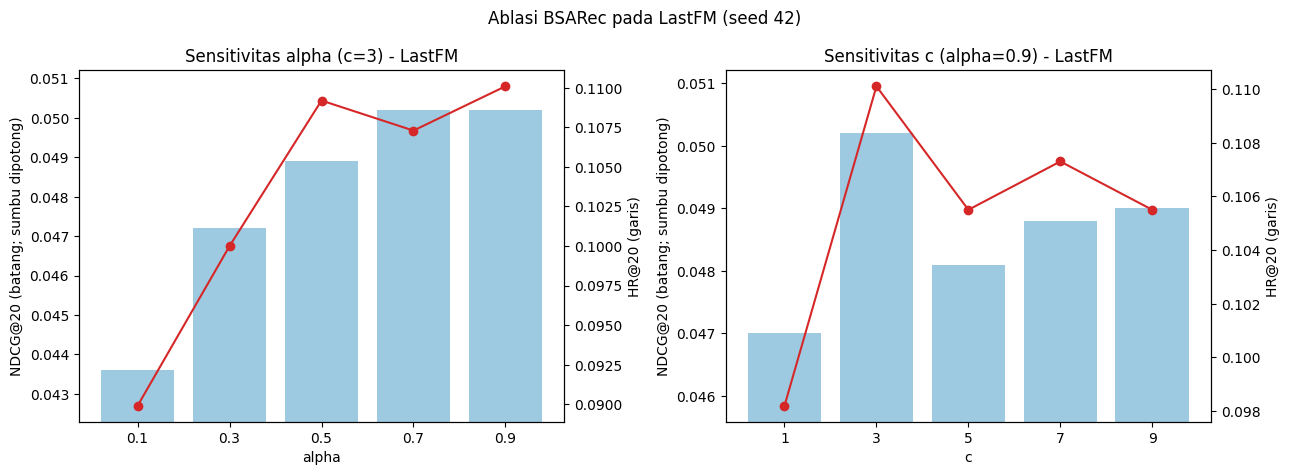

In [22]:
# ==============================================================================
# 1. TUJUAN: Membuat grafik 2 panel (sweep alpha dan sweep c): batang NDCG@20 dan garis HR@20 di
#    sumbu kedua. Sumbu y batang dipotong (min x 0.97 sampai max x 1.02) agar perbedaan kecil
#    terlihat. Disimpan sebagai ablasi_lastfm.png di Drive.
# 2. INPUT/PRASYARAT: Sel H3 sudah dijalankan (TAB_ALPHA, TAB_C). Drive harus ter-mount
#    (jalankan sel backup E atau restore sekali).
# 3. OUTPUT: Grafik tampil di notebook dan file
#    /content/drive/MyDrive/BSARec_backup/ablasi_lastfm.png tersimpan. Normal: batang NDCG@20
#    dengan tinggi mirip (karena sumbu dipotong, selisih tampak besar: lihat tabel H3 sebelum
#    menafsirkan), garis HR@20 bergerak searah.
# 4. AMAN DIULANG?: AMAN DIULANG. Menimpa file PNG lama dengan versi terbaru.
# 5. ESTIMASI WAKTU: beberapa detik.
# 6. KALAU ERROR: RuntimeError Drive: jalankan sel backup E (mount) dulu. Grafik kosong: titik
#    ablasi belum punya hasil (jalankan H1/H2). Peringatan sumbu y terpotong: hanya soal
#    tampilan, selisih sebenarnya ada di tabel H3.
# ==============================================================================

import os
import numpy as np
import matplotlib.pyplot as plt

if not os.path.isdir("/content/drive/MyDrive"):                   # jaga-jaga: jangan membuat folder di disk lokal bila Drive belum ter-mount
    raise RuntimeError("Drive belum ter-mount; jalankan sel backup E (mount) dulu.")
os.makedirs(BACKUP_DIR, exist_ok=True)                            # pastikan folder ada SEBELUM menyimpan

panel = [
    (f"Sensitivitas alpha (c={C}) - {DATA_NAME}", ALPHA_GRID, TAB_ALPHA, "alpha"),
    (f"Sensitivitas c (alpha={ALPHA}) - {DATA_NAME}", C_GRID, TAB_C, "c"),
]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, (judul, xs, df, nama_x) in zip(axes, panel):
    pos = np.arange(len(xs))
    ndcg = df["NDCG@20"].to_numpy(dtype=float)
    hr = df["HR@20"].to_numpy(dtype=float)
    ax.bar(pos, ndcg, color="#9ecae1", label="NDCG@20")           # batang NaN otomatis tidak digambar
    if np.isfinite(ndcg).any():
        ax.set_ylim(np.nanmin(ndcg) * 0.97, np.nanmax(ndcg) * 1.02)   # potong sumbu y agar beda kecil terlihat
    ax.set_xticks(pos)
    ax.set_xticklabels([str(x) for x in xs])
    ax.set_xlabel(nama_x)
    ax.set_ylabel("NDCG@20 (batang; sumbu dipotong)")
    ax.set_title(judul)
    ax2 = ax.twinx()                                              # sumbu y kedua untuk HR@20
    ax2.plot(pos, hr, color="#d62728", marker="o", label="HR@20")
    ax2.set_ylabel("HR@20 (garis)")
fig.suptitle(f"Ablasi BSARec pada {DATA_NAME} (seed {ABLASI_SEED})")
fig.tight_layout()
jalur = os.path.join(BACKUP_DIR, "ablasi_lastfm.png")
fig.savefig(jalur, dpi=150)
print("Grafik disimpan ke:", jalur)
plt.show()

## I. Versi lingkungan

Dicetak untuk bagian "lingkungan eksperimen" di laporan. (Paper memakai Python 3.9.7, PyTorch 1.8.1, CUDA 11.1 pada RTX 3090; lingkungan Colab ini berbeda, sebutkan perbedaannya di laporan.)

In [23]:
# ==============================================================================
# 1. TUJUAN: Mencetak versi Python, PyTorch, CUDA, nama GPU, dan versi paket numpy, scipy, tqdm,
#    wandb untuk dicatat di laporan.
# 2. INPUT/PRASYARAT: Runtime GPU aktif. Tidak bergantung pada sel lain.
# 3. OUTPUT: Teks versi. Yang normal di Colab T4 sesuai catatan: Python 3.13, torch 2.11 (CUDA
#    13.0), GPU 'Tesla T4', numpy 2.1.3, scipy 1.16.3, tqdm 4.67.3, wandb 0.28.1 (bisa berbeda
#    sedikit bila Colab memperbarui image).
# 4. AMAN DIULANG?: AMAN DIULANG (hanya membaca).
# 5. ESTIMASI WAKTU: kurang dari 5 detik.
# 6. KALAU ERROR: Bila 'GPU tidak aktif': ubah runtime lewat menu Runtime > Change runtime type
#    > T4 GPU, lalu jalankan ulang dari A.
# ==============================================================================

import sys, torch

print("Python  :", sys.version.replace("\n", " "))
print("torch   :", torch.__version__)
print("CUDA    :", torch.version.cuda)
if torch.cuda.is_available():
    print("GPU     :", torch.cuda.get_device_name(0))
else:
    print("GPU     : tidak aktif (ubah runtime ke T4 GPU)")
!pip list 2>/dev/null | grep -i -E "numpy|scipy|tqdm|wandb"

Python  : 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
torch   : 2.11.0+cu130
CUDA    : 13.0
GPU     : Tesla T4
numpy                                 2.1.3
scipy                                 1.16.3
tqdm                                  4.67.3
wandb                                 0.28.1


## J. Checkpoint penulis (opsional)

Sel J1 memeriksa apakah ada checkpoint resmi LastFM di `output/` (mis. `BSARec_LastFM_best.pt`, mengikuti pola contoh Beauty di README: `--load_model BSARec_Beauty_best`). **Saat notebook disusun tidak bisa diperiksa apakah repo menyertakan checkpoint seperti itu untuk LastFM.**

- Bila ada: jalankan J2 **sekali saja** (evaluasi saja, tanpa W&B).
- Bila tidak ada: lewati bagian ini; baseline di laporan hanya berasal dari training sendiri (D).

In [24]:
# ==============================================================================
# 1. TUJUAN: Mencari checkpoint (.pt) di output/ yang namanya memuat 'lastfm' dan 'best' (milik
#    penulis), dan menyimpan namanya (tanpa .pt) ke CKPT_PENULIS. Bila tidak ada, CKPT_PENULIS =
#    None dan J2 akan melewati.
# 2. INPUT/PRASYARAT: Sel A1, B1 dijalankan. Bila checkpoint ada, biasanya sudah ikut ter-clone
#    atau diletakkan manual di output/.
# 3. OUTPUT: Daftar checkpoint kandidat atau pesan 'tidak ditemukan'. Normal: sangat mungkin
#    tidak ada (repo tidak tentu menyertakan checkpoint LastFM). Run sendiri
#    (BSARec_LastFM_s42.pt dst.) sengaja tidak dihitung sebagai checkpoint penulis.
# 4. AMAN DIULANG?: AMAN DIULANG (hanya membaca).
# 5. ESTIMASI WAKTU: kurang dari 1 detik.
# 6. KALAU ERROR: Bila output/ belum ada, sel membuatnya kosong dan melaporkan tidak ada
#    checkpoint (bukan error). Bila kandidat lebih dari satu, ubah CKPT_PENULIS manual ke nama
#    yang benar.
# ==============================================================================

import os, glob

os.makedirs(os.path.join(SRC_DIR, "output"), exist_ok=True)
semua_pt = sorted(glob.glob(os.path.join(SRC_DIR, "output", "*.pt")))
# kandidat: nama memuat 'lastfm' dan 'best', dan BUKAN run buatan notebook ini (yang berpola _s<seed> atau _a..._c...)
kandidat = [os.path.basename(f)[:-3] for f in semua_pt
            if "lastfm" in os.path.basename(f).lower() and "best" in os.path.basename(f).lower()]

CKPT_PENULIS = kandidat[0] if kandidat else None
if CKPT_PENULIS is None:
    print("Checkpoint penulis untuk LastFM TIDAK ditemukan di output/. Lewati J2; baseline hanya dari training sendiri.")
else:
    print("Kandidat checkpoint penulis:", kandidat)
    print("Dipakai di J2:", CKPT_PENULIS)

Kandidat checkpoint penulis: ['BSARec_LastFM_best']
Dipakai di J2: BSARec_LastFM_best


In [25]:
# ==============================================================================
# 1. TUJUAN: Mengevaluasi checkpoint penulis pada data test LastFM (python main.py ...
#    --load_model <nama> --do_eval). Tidak memakai W&B.
# 2. INPUT/PRASYARAT: Sel J1 menemukan CKPT_PENULIS. Hyperparameter alpha, c, heads di B1 harus
#    sama dengan yang dipakai penulis untuk checkpoint itu (arsitektur harus cocok agar bobot
#    termuat).
# 3. OUTPUT: Log evaluasi dengan blok 'Load model from ... for test!' lalu dict skor (HR@5 ...
#    NDCG@20). Normal: nilai mendekati angka BSARec di paper Table 2 (bila hyperparameter
#    cocok). Tidak ada log baru yang dipakai oleh bagian F-G.
# 4. AMAN DIULANG?: JALANKAN SEKALI SAJA (hasil tidak disimpan ke tabel; mengulang hanya
#    membuang waktu). Tidak menimpa file lain.
# 5. ESTIMASI WAKTU: sekitar 1-3 menit.
# 6. KALAU ERROR: 'size mismatch' saat load: alpha/c/heads/hidden_size di B1 tidak sama dengan
#    yang dipakai penulis: sesuaikan lalu ulangi. FileNotFoundError: nama checkpoint salah,
#    periksa J1. Bila J1 menyatakan tidak ada checkpoint, sel ini sengaja tidak berbuat apa-apa.
# ==============================================================================

if CKPT_PENULIS is None:
    print("Tidak ada checkpoint penulis, sel dilewati.")
else:
    perintah = (f"python main.py --data_name {DATA_NAME} --alpha {ALPHA} --c {C} "
                f"--num_attention_heads {NUM_HEADS} --load_model {CKPT_PENULIS} --do_eval")
    if NUM_WORKERS is not None:
        perintah += f" --num_workers {NUM_WORKERS}"
    print("Menjalankan:", perintah)
    get_ipython().system(perintah)   # setara '!python main.py ...'; output tampil langsung

Menjalankan: python main.py --data_name LastFM --alpha 0.9 --c 3 --num_attention_heads 1 --load_model BSARec_LastFM_best --do_eval --num_workers 2
2026-10-29 21:21:42,126 - Namespace(data_dir='./data/', output_dir='output/', data_name='LastFM', do_eval=True, load_model='BSARec_LastFM_best', train_name='Oct-29-2026_21-21-42', num_items=10, num_users=1091, lr=0.001, batch_size=256, epochs=200, no_cuda=False, log_freq=1, patience=10, num_workers=2, seed=42, weight_decay=0.0, adam_beta1=0.9, adam_beta2=0.999, gpu_id='0', variance=5, model_type='BSARec', max_seq_length=50, hidden_size=64, num_hidden_layers=2, hidden_act='gelu', num_attention_heads=1, attention_probs_dropout_prob=0.5, hidden_dropout_prob=0.5, initializer_range=0.02, c=3, alpha=0.9, cuda_condition=True, data_file='./data/LastFM.txt', item_size=3647, checkpoint_path='output/Oct-29-2026_21-21-42.pt', same_target_path='./data/LastFM_same_target.npy')
2026-10-29 21:21:42,137 - BSARecModel(
  (item_embeddings): Embedding(3647, 64,